# 7. Modelo final e análises

← [Curvas de treinamento](06_training_curves.ipynb) · [índice](README.pt-BR.md) · [Auditoria de rótulos](08_label_noise_audit.ipynb) →

Escolha do modelo final e análises complementares: matriz de confusão, confiança e calibração, erros, Grad-CAM, espelhamento e custo computacional.

## Melhor modelo

O modelo final é o de maior acurácia de validação. O conjunto de teste não entra
na escolha, apenas é reportado. Esse é o modelo salvo em `outputs/weights/best_model.pt` e usado
no notebook de predições.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from svhn_utils import figures_dir, RESULTS_DIR, get_device, load_data, load_model, load_results, predict, predict_proba
FIG_DIR = figures_dir("07_final_model")   # figuras deste notebook em outputs/figures/07_final_model/

device = get_device()
data, _ = load_data()
results = load_results()

In [2]:
best_id = max(results, key=lambda i: results[i]["val_acc"])
best = results[best_id]
print(f"Melhor experimento: {best_id}: {best['desc']}")
print(f"  arquitetura: {best['arch']} {best['model_kw']}")
print(f"  hiperparâmetros: {best['train_cfg']}")
print(f"  parâmetros treináveis: {best['params']:,}")
print(f"  melhor época: {best['best_epoch']} de {best['epochs_run']}")
print(f"  acurácia treino:    {best['train_acc']*100:.2f}%")
print(f"  acurácia validação: {best['val_acc']*100:.2f}%")
print(f"  acurácia teste:     {best['test_acc']*100:.2f}%")

Melhor experimento: E16: mais filtros (64-128-256)
  arquitetura: vgg {'channels': [64, 128, 256], 'convs_per_block': 2, 'batchnorm': True, 'dropout': 0.5, 'conv_dropout': 0.1}
  hiperparâmetros: {'optimizer': 'adam', 'lr': 0.001, 'batch_size': 128, 'epochs': 40, 'patience': 40, 'scheduler': 'onecycle', 'augment': True, 'weight_decay': 0.0, 'seed': 0}
  parâmetros treináveis: 2,197,962
  melhor época: 32 de 40
  acurácia treino:    98.82%
  acurácia validação: 96.07%
  acurácia teste:     97.13%


acurácia no teste (modelo recarregado): 97.13%


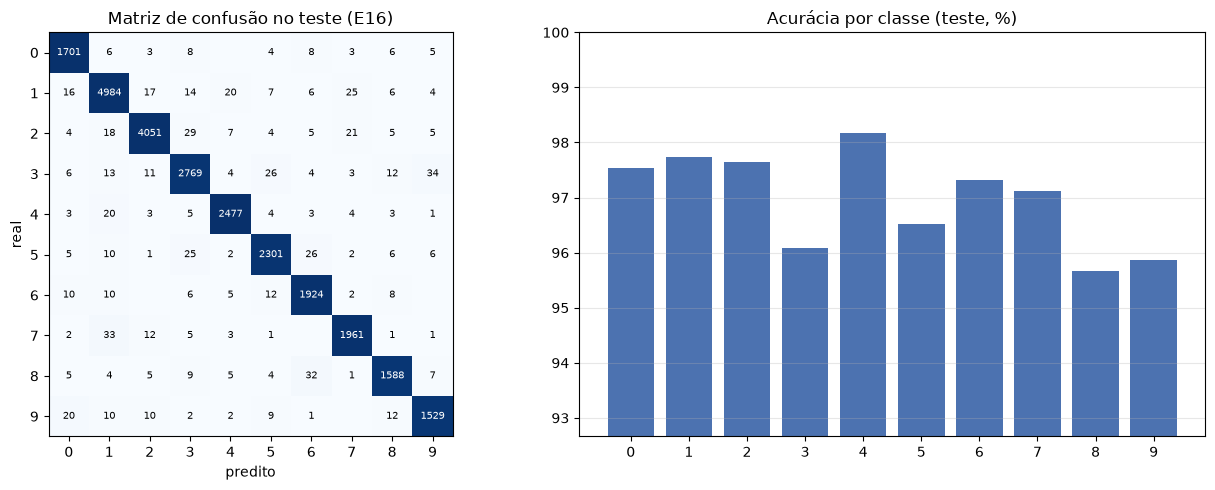

In [3]:
# recarrega exatamente o arquivo salvo, para garantir que ele reproduz o resultado
model, norm, ckpt = load_model("best_model", device)   # baixa do Hugging Face se não estiver em outputs/weights/
assert ckpt["experiment"] == best_id

Xte, yte = (t.to(device) for t in data["test"])
pred = predict(model, Xte, norm).cpu(); yte_c = yte.cpu()
print(f"acurácia no teste (modelo recarregado): {(pred == yte_c).float().mean()*100:.2f}%")

cm = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(yte_c, pred): cm[t, p] += 1
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cmn = cm.float() / cm.sum(1, keepdim=True)
im = axes[0].imshow(cmn, cmap="Blues")
for a in range(10):
    for b in range(10):
        if cm[a, b] > 0:
            axes[0].text(b, a, cm[a, b].item(), ha="center", va="center", fontsize=7,
                         color="white" if cmn[a, b] > .5 else "black")
axes[0].set_xticks(range(10)); axes[0].set_yticks(range(10))
axes[0].set_xlabel("predito"); axes[0].set_ylabel("real"); axes[0].set_title(f"Matriz de confusão no teste ({best_id})")
per_class = cm.diag().float() / cm.sum(1)
axes[1].bar(range(10), per_class * 100, color="#4C72B0"); axes[1].set_ylim(per_class.min() * 100 - 3, 100)
axes[1].set_xticks(range(10)); axes[1].set_title("Acurácia por classe (teste, %)"); axes[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_best_model.png", dpi=150); plt.show()

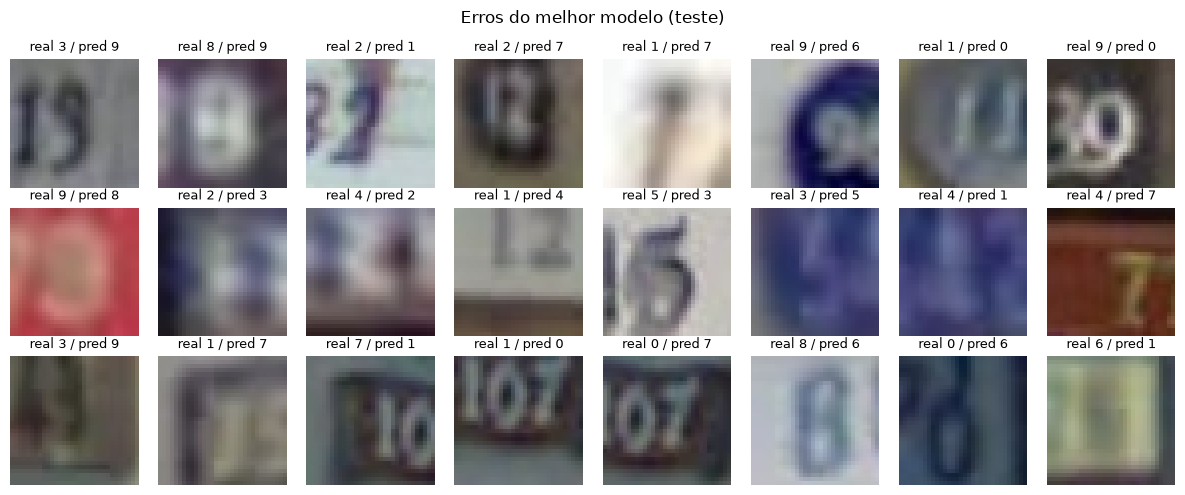

In [4]:
# exemplos de erros do melhor modelo no teste
wrong = (pred != yte_c).nonzero().squeeze(1)[:24]
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(data["test"][0][i].permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"real {yte_c[i].item()} / pred {pred[i].item()}", fontsize=9)
plt.suptitle("Erros do melhor modelo (teste)"); plt.tight_layout()
plt.savefig(FIG_DIR / "errors_best_model.png", dpi=150); plt.show()

## Análises complementares do modelo final

Todas as análises desta seção usam apenas o modelo final já treinado (`best_model.pt`) e o conjunto de teste.
Nenhuma delas altera o modelo ou a sua escolha.

### Matriz de confusão normalizada e confiança das predições

A matriz normalizada por linha mostra, para cada dígito real, a porcentagem de imagens atribuída a cada classe.
Assim, as classes podem ser comparadas mesmo com tamanhos diferentes no teste.

A confiança de uma predição é a maior probabilidade da softmax. O gráfico de confiabilidade compara a
confiança média com a acurácia real em faixas de confiança. O **ECE** (*expected calibration error*) é a
média ponderada dessa diferença: quanto mais próximo de 0, mais as probabilidades refletem a chance real de acerto.

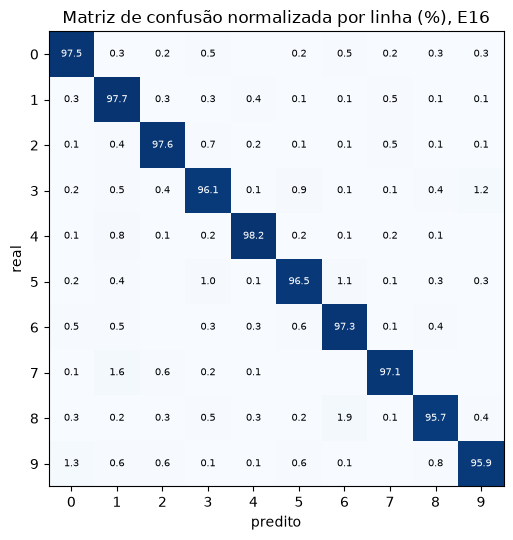

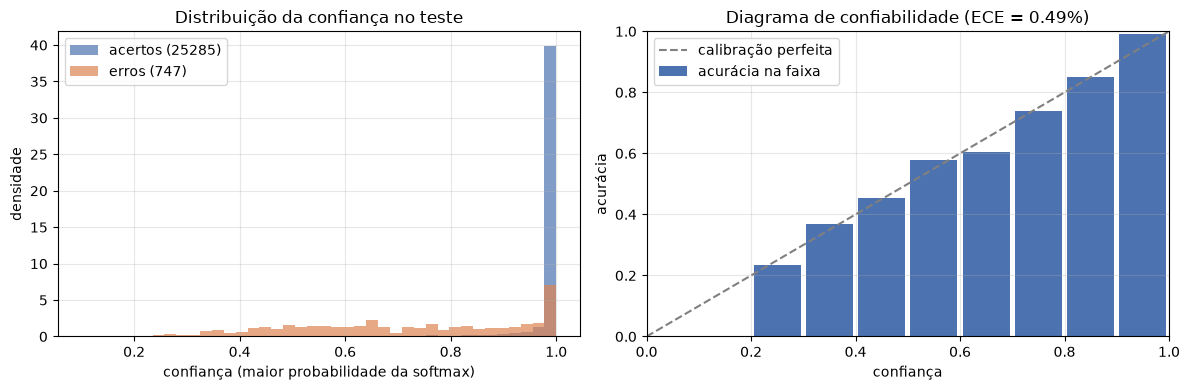

confiança média: acertos 98.3% | erros 71.6%
confiança mediana: acertos 100.0% | erros 72.4%
erros com confiança > 0.50: 604 de 747 (80.9%) | acertos com confiança > 0.50: 99.6%
erros com confiança > 0.90: 209 de 747 (28.0%) | acertos com confiança > 0.90: 95.4%
erros com confiança > 0.99: 94 de 747 (12.6%) | acertos com confiança > 0.99: 85.4%
imagens com confiança > 0.90: 93.4% do teste, acurácia 99.14%
imagens com confiança > 0.99: 83.3% do teste, acurácia 99.57%
ECE: 0.49%


In [5]:
probs = predict_proba(model, Xte, norm)
conf, pred_p = probs.max(1)
ok = pred_p == yte_c
assert torch.equal(pred_p, pred)

# matriz normalizada por linha (%)
cm_pct = cm.float() / cm.sum(1, keepdim=True) * 100
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm_pct, cmap="Blues", vmax=100)
for a in range(10):
    for b in range(10):
        v = cm_pct[a, b].item()
        if v >= 0.05:
            ax.text(b, a, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if v > 50 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("predito"); ax.set_ylabel("real"); ax.set_title(f"Matriz de confusão normalizada por linha (%), {best_id}")
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_normalized.png", dpi=150); plt.show()

# confiança: acertos x erros e diagrama de confiabilidade
bins = np.linspace(0, 1, 11)
idx = np.clip(np.digitize(conf.numpy(), bins) - 1, 0, 9)
acc_bin, conf_bin, n_bin = [], [], []
for b in range(10):
    m = idx == b
    n_bin.append(m.sum())
    acc_bin.append(ok.numpy()[m].mean() if m.any() else np.nan)
    conf_bin.append(conf.numpy()[m].mean() if m.any() else np.nan)
n_bin = np.array(n_bin)
ece = np.nansum(n_bin / n_bin.sum() * np.abs(np.array(acc_bin) - np.array(conf_bin)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(conf[ok].numpy(), bins=40, range=(0.1, 1), alpha=.7, label=f"acertos ({ok.sum().item()})", color="#4C72B0", density=True)
axes[0].hist(conf[~ok].numpy(), bins=40, range=(0.1, 1), alpha=.7, label=f"erros ({(~ok).sum().item()})", color="#DD8452", density=True)
axes[0].set_xlabel("confiança (maior probabilidade da softmax)"); axes[0].set_ylabel("densidade")
axes[0].set_title("Distribuição da confiança no teste"); axes[0].legend()
centers = (bins[:-1] + bins[1:]) / 2
axes[1].bar(centers, acc_bin, width=0.09, color="#4C72B0", label="acurácia na faixa")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="calibração perfeita")
axes[1].set_xlabel("confiança"); axes[1].set_ylabel("acurácia"); axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1)
axes[1].set_title(f"Diagrama de confiabilidade (ECE = {ece*100:.2f}%)"); axes[1].legend(loc="upper left")
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "confidence.png", dpi=150); plt.show()

c_ok, c_err = conf[ok], conf[~ok]
print(f"confiança média: acertos {c_ok.mean()*100:.1f}% | erros {c_err.mean()*100:.1f}%")
print(f"confiança mediana: acertos {c_ok.median()*100:.1f}% | erros {c_err.median()*100:.1f}%")
for t in [0.5, 0.9, 0.99]:
    print(f"erros com confiança > {t:.2f}: {(c_err > t).sum().item()} de {len(c_err)} ({(c_err > t).float().mean()*100:.1f}%)"
          f" | acertos com confiança > {t:.2f}: {(c_ok > t).float().mean()*100:.1f}%")
for t in [0.9, 0.99]:
    m = conf > t
    print(f"imagens com confiança > {t:.2f}: {m.float().mean()*100:.1f}% do teste, acurácia {ok[m].float().mean()*100:.2f}%")
print(f"ECE: {ece*100:.2f}%")

### Análise visual dos erros

O mosaico mostra os 6 erros com maior confiança e os 6 com menor confiança. Cada título traz o
rótulo real, a predição e a confiança da predição.

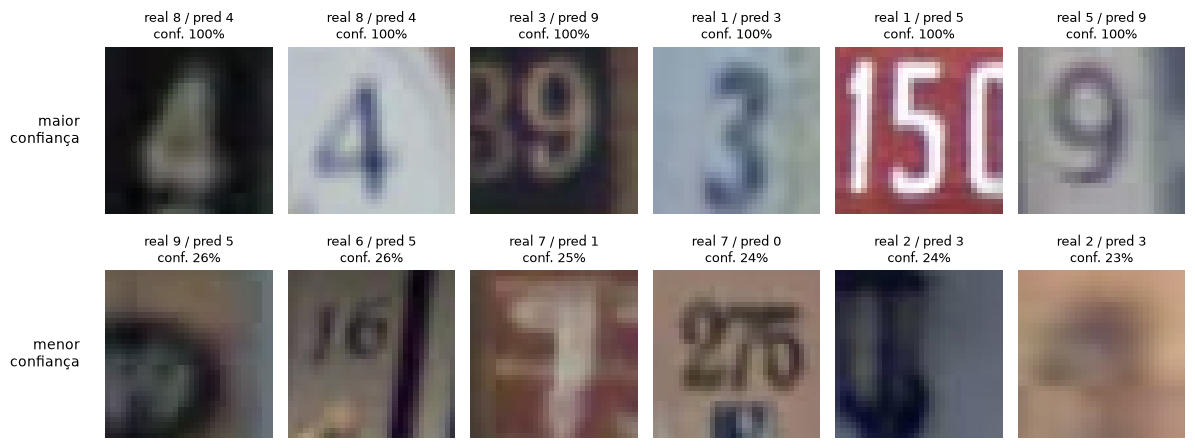

índices no teste: [22882, 20757, 15843, 6492, 1317, 3251, 14517, 8279, 10117, 18087, 20205, 3083]


In [6]:
err_idx = (~ok).nonzero().squeeze(1)
order = err_idx[conf[err_idx].argsort(descending=True)]
sel = torch.cat([order[:6], order[-6:]])
fig, axes = plt.subplots(2, 6, figsize=(12, 4.8))
for k, (ax, i) in enumerate(zip(axes.flat, sel)):
    ax.imshow(data["test"][0][i].permute(1, 2, 0)); ax.axis("off")
    ax.set_title(f"real {yte_c[i].item()} / pred {pred[i].item()}\nconf. {conf[i]*100:.0f}%", fontsize=9)
axes[0, 0].text(-0.15, 0.5, "maior\nconfiança", transform=axes[0, 0].transAxes, ha="right", va="center", fontsize=10)
axes[1, 0].text(-0.15, 0.5, "menor\nconfiança", transform=axes[1, 0].transAxes, ha="right", va="center", fontsize=10)
plt.tight_layout(); plt.savefig(FIG_DIR / "errors_by_confidence.png", dpi=150); plt.show()
print("índices no teste:", sel.tolist())

### Grad-CAM: onde a CNN olha

O Grad-CAM calcula, para a classe predita, o gradiente do *score* em relação aos mapas de ativação da
última camada convolucional (8×8×256, antes do último pooling). Cada mapa recebe como peso a média do
seu gradiente, e a soma ponderada passa por uma ReLU. O resultado é ampliado para 32×32 e sobreposto à
imagem: as regiões quentes são as que mais aumentam o *score* da classe predita.

Para medir isso em todo o teste, calculo a fração da ativação do Grad-CAM que cai na faixa central da
imagem (colunas 8 a 23, ou seja, 50% da largura), onde fica o dígito rotulado no SVHN.

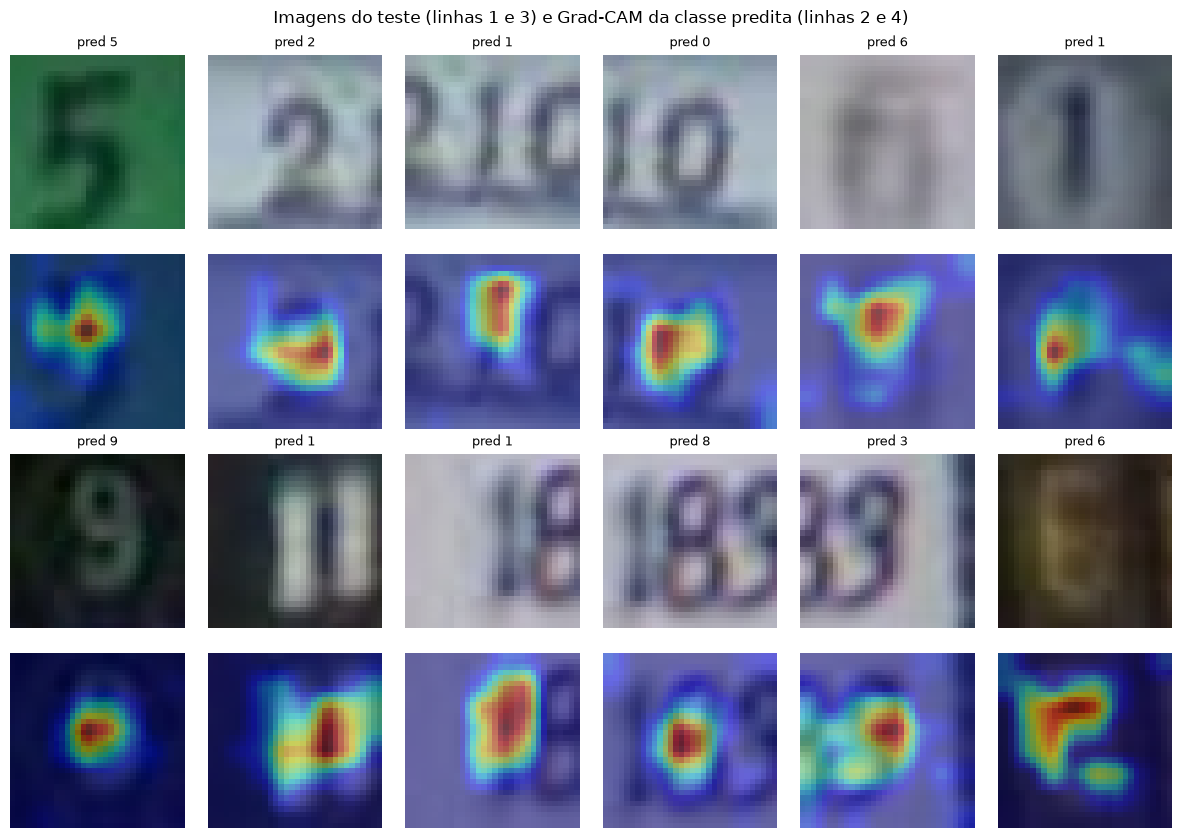

fração média da ativação Grad-CAM na faixa central (50% da largura): 83.9%
  acertos: 84.3% | erros: 69.6%
imagens com mais da metade da ativação na faixa central: 99.1%


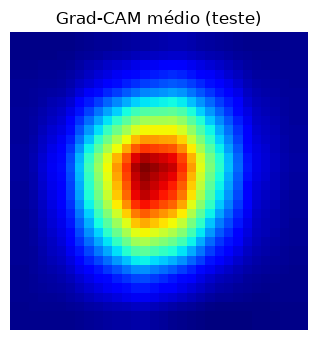

In [7]:
target_layer = model.features[-3]          # última ReLU do bloco 3 (8x8x256), antes do max pool
assert isinstance(target_layer, nn.ReLU)

def grad_cam(model, x_norm):
    acts = {}
    def fwd_hook(m, i, o):
        acts["a"] = o
        o.register_hook(lambda g: acts.__setitem__("g", g))
    h = target_layer.register_forward_hook(fwd_hook)
    model.eval(); model.zero_grad()
    logits = model(x_norm)
    cls = logits.argmax(1)
    logits.gather(1, cls[:, None]).sum().backward()
    h.remove()
    w = acts["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(32, 32), mode="bilinear", align_corners=False)[:, 0]
    cam = cam / (cam.flatten(1).max(1).values[:, None, None] + 1e-8)
    return cam.detach().cpu(), cls.cpu()

# exemplos: 12 primeiras imagens do teste acertadas
ex = ok.nonzero().squeeze(1)[:12]
cams, cls = grad_cam(model, norm(Xte[ex.to(device)]))
fig, axes = plt.subplots(4, 6, figsize=(12, 8.5))
for k, i in enumerate(ex):
    r, c = (k // 6) * 2, k % 6
    img = data["test"][0][i].permute(1, 2, 0)
    axes[r, c].imshow(img); axes[r, c].set_title(f"pred {cls[k].item()}", fontsize=9)
    axes[r + 1, c].imshow(img); axes[r + 1, c].imshow(cams[k], cmap="jet", alpha=0.45)
for ax in axes.flat: ax.axis("off")
plt.suptitle("Imagens do teste (linhas 1 e 3) e Grad-CAM da classe predita (linhas 2 e 4)")
plt.tight_layout(); plt.savefig(FIG_DIR / "gradcam.png", dpi=150); plt.show()

# medida em todo o conjunto de teste
all_cams = []
for s in range(0, len(Xte), 512):
    c_, _ = grad_cam(model, norm(Xte[s:s + 512]))
    all_cams.append(c_)
all_cams = torch.cat(all_cams)
mass = all_cams.sum(dim=(1, 2))
center_frac = all_cams[:, :, 8:24].sum(dim=(1, 2)) / mass
print(f"fração média da ativação Grad-CAM na faixa central (50% da largura): {center_frac.mean()*100:.1f}%")
print(f"  acertos: {center_frac[ok].mean()*100:.1f}% | erros: {center_frac[~ok].mean()*100:.1f}%")
print(f"imagens com mais da metade da ativação na faixa central: {(center_frac > 0.5).float().mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.imshow(all_cams.mean(0), cmap="jet"); ax.set_title("Grad-CAM médio (teste)"); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "gradcam_mean.png", dpi=150); plt.show()

### Por que não usar espelhamento horizontal

Para verificar a decisão de não usar *flip* horizontal, apliquei o modelo final às imagens de teste
espelhadas e comparei a acurácia por classe. Como o modelo foi treinado sem espelhamento, uma queda
é esperada em todas as classes. A comparação útil é entre classes: dígitos com simetria horizontal
aproximada (0, 1 e 8) continuam reconhecíveis depois de espelhados, enquanto dígitos assimétricos
(2, 3, 4, 5, 6, 7 e 9) viram outro símbolo ou um símbolo inválido.

acurácia no teste: original 97.13% | espelhado 40.84%


,dígito,original (%),espelhado (%)
0,0,97.529999,94.320000
1,1,97.739998,89.699997
2,2,97.639999,10.650000
3,3,96.080002,11.030000
4,4,98.180000,66.900002
5,5,96.519997,0.670000
6,6,97.320000,9.410000
7,7,97.129997,5.350000
8,8,95.660004,95.480003
9,9,95.860001,4.330000


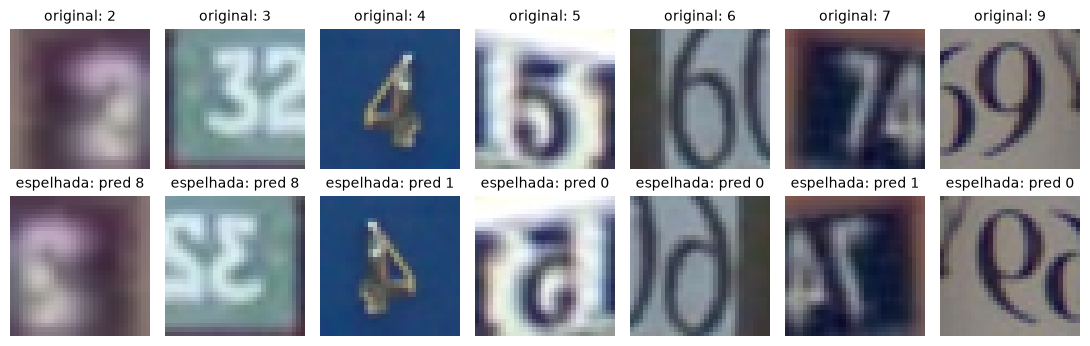

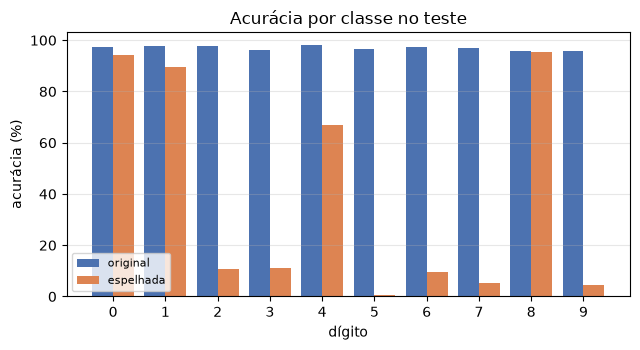

In [8]:
Xte_flip = torch.flip(Xte, dims=[3])
pred_flip = predict(model, Xte_flip, norm).cpu()
acc_orig = torch.tensor([(pred[yte_c == c] == c).float().mean() for c in range(10)]) * 100
acc_flip = torch.tensor([(pred_flip[yte_c == c] == c).float().mean() for c in range(10)]) * 100
print(f"acurácia no teste: original {(pred == yte_c).float().mean()*100:.2f}% | espelhado {(pred_flip == yte_c).float().mean()*100:.2f}%")
flip_tab = pd.DataFrame({"dígito": range(10), "original (%)": acc_orig.numpy().round(2),
                         "espelhado (%)": acc_flip.numpy().round(2)})
display(flip_tab)

digits = [2, 3, 4, 5, 6, 7, 9]
fig, axes = plt.subplots(2, 7, figsize=(11, 3.6))
for k, d in enumerate(digits):
    i = ((yte_c == d) & ok).nonzero().squeeze(1)[3]
    axes[0, k].imshow(data["test"][0][i].permute(1, 2, 0)); axes[0, k].set_title(f"original: {d}", fontsize=10)
    axes[1, k].imshow(torch.flip(data["test"][0][i], dims=[2]).permute(1, 2, 0))
    axes[1, k].set_title(f"espelhada: pred {pred_flip[i].item()}", fontsize=10)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "flip_examples.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.6))
xs = np.arange(10)
ax.bar(xs - 0.2, acc_orig, 0.4, label="original", color="#4C72B0")
ax.bar(xs + 0.2, acc_flip, 0.4, label="espelhada", color="#DD8452")
ax.set_xticks(xs); ax.set_ylabel("acurácia (%)"); ax.set_xlabel("dígito")
ax.set_title("Acurácia por classe no teste"); ax.legend(fontsize=8, loc="lower left"); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(FIG_DIR / "flip_accuracy.png", dpi=150); plt.show()

### Custo computacional e desempenho

Tempo por época e tempo total medidos durante o treino (GPU Apple M5 via MPS). O tempo por época inclui
a avaliação em treino e em validação ao final de cada época. Os tempos de E3 e E11 estão inflados por
fatores externos (execução dentro do kernel Jupyter e limitação de desempenho com bateria baixa) e não
devem ser comparados com os demais.

tempo total de treino dos 17 experimentos: 172 min


,Exp.,Modificação,Parâmetros,Épocas,s/época,Tempo total (min),Acc val. (%),Acc teste (%)
0,E1,MLP baseline (3072-512-256-10),1707274,30,1.2,0.6,82.58,80.02
1,E2,MLP + BatchNorm + Dropout 0.3,1708042,30,1.1,0.6,85.67,83.85
2,E3,CNN baseline (LeNet-like),1105098,17,30.7,8.7,89.18,88.42
3,E4,CNN VGG-like (3 blocos × 2 conv3x3),814122,14,14.8,3.4,92.53,92.70
4,E5,+ BatchNorm,814826,27,20.0,9.0,93.02,92.62
5,E6,"+ Dropout (0.5 FC, 0.1 conv)",814826,30,20.9,10.4,95.03,95.29
6,E7,+ Data Augmentation,814826,40,16.7,11.1,95.74,96.45
7,E8,SGD+Momentum 0.9 (lr 0.05),814826,40,17.7,11.8,95.54,96.58
8,E9,SGD sem momentum (lr 0.05),814826,40,17.1,11.4,94.72,95.97
9,E10,+ LR decay (÷10 no platô),814826,40,16.7,11.1,95.65,96.86


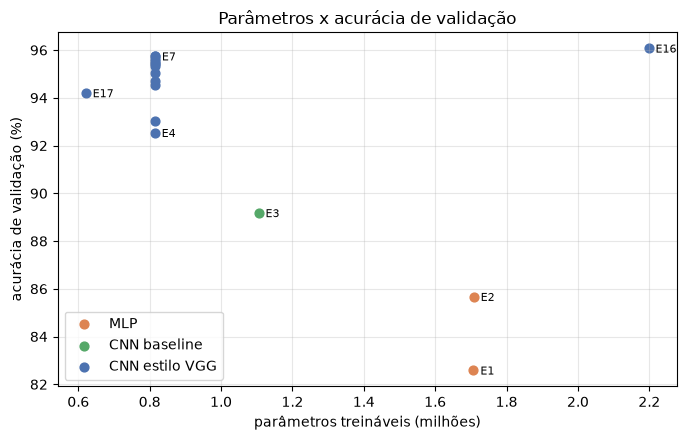

In [9]:
cost = pd.DataFrame([{
    "Exp.": i, "Modificação": r["desc"], "Parâmetros": r["params"],
    "Épocas": r["epochs_run"], "s/época": round(r["sec_per_epoch"], 1),
    "Tempo total (min)": round(sum(r["history"]["time"]) / 60, 1),
    "Acc val. (%)": round(r["val_acc"] * 100, 2), "Acc teste (%)": round(r["test_acc"] * 100, 2),
} for i, r in results.items()])
cost.to_csv(RESULTS_DIR / "compute_cost.csv", index=False)
print(f"tempo total de treino dos 17 experimentos: {cost['Tempo total (min)'].sum():.0f} min")
display(cost)

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = {"mlp": "#DD8452", "simple_cnn": "#55A868", "vgg": "#4C72B0"}
labels = {"mlp": "MLP", "simple_cnn": "CNN baseline", "vgg": "CNN estilo VGG"}
for arch in colors:
    sub = [(r["params"] / 1e6, r["val_acc"] * 100, i) for i, r in results.items() if r["arch"] == arch]
    ax.scatter([s[0] for s in sub], [s[1] for s in sub], color=colors[arch], label=labels[arch], s=40)
    for x, y, i in sub:
        if i in {"E1", "E2", "E3", "E4", "E7", "E16", "E17"}:
            ax.annotate(i, (x, y), textcoords="offset points", xytext=(5, -3), fontsize=8)
ax.set_xlabel("parâmetros treináveis (milhões)"); ax.set_ylabel("acurácia de validação (%)")
ax.set_title("Parâmetros x acurácia de validação"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "params_vs_accuracy.png", dpi=150); plt.show()

### Resumo das análises complementares

- **Matriz normalizada:** a acurácia por classe vai de 95,7% (dígito 8) a 98,2% (dígito 4). As maiores confusões são o 8 lido como 6 (1,9%), o 7 como 1 (1,6%), o 9 como 0 (1,3%) e o 3 como 9 (1,2%).
- **Confiança:** a confiança média é de 98,3% nos acertos e de 71,6% nos erros. 72% dos erros têm confiança abaixo de 0,9, mas 94 erros (12,6%) passam de 0,99. ECE = 0,49%, ou seja, as probabilidades estão bem calibradas.
- **Erros:** nos 6 erros de maior confiança, o dígito predito é o que aparece no centro da imagem. Em 4 deles, a imagem mostra só o dígito predito (possível erro de rótulo ou de recorte). Nos outros 2, o rótulo corresponde ao dígito vizinho à esquerda. Os erros de menor confiança aparecem em imagens borradas, escuras ou com pouco contraste.
- **Grad-CAM:** 83,9% da ativação, em média, cai na faixa central (contra 50% se a ativação fosse uniforme), e 99,1% das imagens têm mais da metade da ativação nessa faixa. Nos erros, a média cai para 69,6%.
- **Espelhamento:** a acurácia no teste espelhado cai para 40,84%. Os dígitos 0, 1 e 8 continuam sendo reconhecidos (94,3%, 89,7% e 95,5%), enquanto os assimétricos caem para algo entre 0,7% e 11,0%, com exceção do 4 (66,9%). Isso confirma que o flip horizontal não é uma augmentation válida para dígitos.
- **Custo:** os 17 experimentos somaram 172 min de treino. A VGG com 814 mil parâmetros (E7) supera a MLP de 1,7 milhão em mais de 10 p.p. O modelo final tem 2,7× mais parâmetros que a E7 e leva 2,6× mais tempo por época, para +0,33 p.p. na validação.

## Conclusões

**Qual abordagem funcionou melhor.** As CNNs superaram claramente a MLP: a melhor MLP chegou
a 85,7% de validação, contra 89,2% da CNN mais simples e 96,1% da melhor CNN. A convolução
compartilha pesos e preserva a vizinhança espacial, o que torna a rede robusta a pequenas
translações dos dígitos.

**Modelo final: E16**, uma CNN estilo VGG com 3 blocos de 2 convoluções 3×3 (64, 128 e 256 filtros),
BatchNorm, Dropout (0,5 nas FC e 0,1 nas conv), data augmentation, Adam com lr máxima de 1e-3,
OneCycle, batch 128, 40 épocas e 2,2 milhões de parâmetros.
- acurácia de validação de **96,07%**, a maior entre todos os experimentos e o critério de escolha;
- acurácia de teste de **97,13%**;
- o gap entre treino e validação é pequeno (98,8% e 96,1%), as curvas são estáveis e não há sinal de overfitting.

**Modificações com maior impacto**, medidas pelo ganho na acurácia de validação:

| Modificação | Ganho |
|---|---|
| Trocar a MLP por uma CNN | +6,6 p.p. |
| Trocar a CNN baseline pela arquitetura estilo VGG (convs 3×3 empilhadas) | +3,4 p.p. |
| Dropout | +2,0 p.p. |
| Data augmentation | +0,7 p.p., e fez o gap entre treino e validação cair de 4,1 para 1,7 p.p. |
| Mais filtros (64-128-256) | +0,3 p.p. |

**Modificações que não ajudaram ou pioraram.**
- **Otimizador:** trocar o Adam por SGD com momentum não mudou o resultado (−0,2 p.p.). Remover o momentum piorou (−0,8 p.p.) e deixou o treino instável.
- **Taxa de aprendizado:** lr muito baixa (−1,2 p.p.) e muito alta (−0,3 p.p.) pioraram. Entre os valores testados (1e-4, 1e-3 e 1e-2), o lr = 1e-3, o valor padrão do Adam, foi o melhor.
- **Decaimento da lr (plateau e OneCycle):** praticamente não mudou a acurácia (±0,1 p.p.), mas deixou as curvas mais estáveis.
- **Tamanho do batch:** 32 e 512 ficaram ligeiramente abaixo de 128.
- **Menos camadas (1 conv por bloco):** reduziu a capacidade da rede e piorou o resultado (−1,6 p.p.).

**Erros do modelo final.** Pela matriz de confusão, as confusões mais comuns são entre 3 e 9, entre 3 e 5, o 7 lido como 1 e o 8 lido como 6.
São pares visualmente parecidos, principalmente em imagens borradas ou de baixo contraste. Muitos
erros também acontecem em imagens com dígitos vizinhos visíveis ou com rótulos ambíguos.

**Principais dificuldades.**
- **Sobreajuste rápido** das CNNs sem regularização: com BatchNorm, o treino chega a 99,6% em poucas épocas. Foi necessário combinar Dropout, data augmentation e early stopping.
- **Augmentation adequada a dígitos:** não usar flip horizontal e limitar rotação e translação para não descaracterizar o dígito nem trazer o dígito vizinho para o centro.
- **Custo computacional:** cada experimento com augmentation leva de 10 a 30 min na GPU do notebook (Apple M5/MPS). Por isso foi preciso planejar experimentos que mudassem uma coisa por vez.